# Search and download **CLMS HR-Water, Snow and Ice (WSI)** snow products using the OData API from the Copernicus Data Space Ecosystem (CDSE)

This Jupyter notebook provides a basic hands-on introduction to searching, downloading, and exploring High Resolution Water, Snow and Ice (HR-WSI) products. It focuses on the use of the Open Data Protocol OData API and is organized into two sections:
- A) Getting familiar with the OData API
- B) Exploring HR-WSI snow products

Users can first visit the Copernicus Data Space Ecosystem (CDSE) Browser interface to explore and familiarize themselves with the available products.

**Authors**: Florence Marti & Matthieu Denisselle (Magellium), Cemal Melih Tanis (Finnish Meteorological Institute)

**Contact**: https://land.copernicus.eu/en/contact-service-helpdesk 

**Prerequisites**
Before starting, please complete the following steps:
- Create an account on the CDSE interface: https://dataspace.copernicus.eu/
- Access your CDSE JupyterLab environment: https://dataspace.copernicus.eu/analyse/jupyterlab and select a Medium or Large server.

*NB*: Files stored in the CDSE JupyterLab default working directory ('home') are not persistent and will be deleted automatically when the session ends. If you wish to save your work, please upload your data to the 'mystorage' folder. 
- In the left panel, create a new folder inside the 'mystorage' directory.
- Upload this Jupyter notebook by dragging and dropping it into the newly created folder.
- Upload the associated shapefile to the same folder (it must include .dbf, .prj, .shx and .shp)
- Upload to the same folder a text file named *odata_clms_hr_water_snow_ice_credentials_credentials.txt* containing your authentication credentials in the following format:
  
*username=email@address.com*  
*password=mypassword*

- Select the **Geo** Science kernel from the kernel selector in the top-right corner of the interface.

# A. Discover the CDSE Odata API to access the HR-WSI products 
In this section, we will: 
1. Explore the available snow datasets
2. Set the search parameters and configure the request
3. Execute the request
4. Download data
5. Modify the request to add a cloud percentage filter


## 1. The CLMS datasets on the CDSE Odata API
The different CLMS collection datasets are listed here: https://documentation.dataspace.copernicus.eu/Data/CopernicusServices/CLMS.html  
**More information on the CLMS HR-WSI snow portfolio**: https://land.copernicus.eu/en/products/snow

The HR-WSI snow datasets are:

In [1]:
### Snow cover
fsc = {'short_name': 'FSC', 'full_name': 'Fractional Snow Cover', 'dataset_id': "clms_wsi_fractional-snow-cover_europe_utm_20m_daily_v2"}
gfsc = {'short_name': 'GFSC', 'full_name': 'Gap-filled Fractional Snow Cover', 'dataset_id': "clms_wsi_gap-filled-fractional-snow-cover_europe_utm_60m_daily_v1"}

### Snow state
sws = {'short_name': 'SWS', 'full_name': 'SAR Wet Snow in high mountain areas', 'dataset_id': "clms_wsi_sar-wet-snow_europe_utm_60m_daily_v2"}
wds = {'short_name': 'WDS', 'full_name': 'Wet/Dry Snow', 'dataset_id': "clms_wsi_wet-dry-snow_europe_utm_60m_daily_v2"}

### Snow phenology
sps2 = {'short_name': 'SPS2', 'full_name': 'Snow Phenology based on Sentinel-2', 'dataset_id': "clms_wsi_snow-phenology-s2_europe_utm_20m_yearly_v1"}
sps1s2 = {'short_name': 'SPS1S2', 'full_name': 'Snow Phenology based on Sentinel-1 & 2 - in high mountain areas', 'dataset_id': "clms_wsi_snow-phenology-s1-s2_europe_utm_60m_yearly_v1"}

### Cloud cover
cc = {'short_name': 'CC', 'full_name': 'Cloud classification Sentinel-2', 'dataset_id': "clms_wsi_cloud-classification_europe_utm_20m_daily_v1"}

HRWSI_snow_collection= {'FSC': fsc, 'GFSC': gfsc, 'SWS': sws, 'WDS': wds, 'SPS2': sps2, 'SPS1S2': sps1s2, 'CC': cc}

## 2. Set the search parameters and configure the request

In [2]:
# Define which product will be requested
dataset_id = HRWSI_snow_collection['FSC']['dataset_id']

# Define start and end date of interest
start_date = "2026-01-01"
end_date = "2026-05-18"

# Define an area of interest as WKT polygon (you can rely on the "create an area of interest" tool in the upper-right panel of the CDSE Browser)
aoi = "POLYGON((6.726379 45.792425,6.726379 45.51982, 7.792053 45.531365,7.789307 45.960697,6.726379 45.792425))"

# Filter for the data collection OData
# uses "greater than" (gt), "less than" (lt) to set the date range
params = {
    "$select": "Name,Id", # to only keep the products name, the product ID in the output result
    "$filter": (
        f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'datasetIdentifier' and att/OData.CSC.StringAttribute/Value eq '{dataset_id}') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{aoi}') and "
        f"ContentDate/Start gt '{start_date}T00:00:00.000Z' and "
        f"ContentDate/Start lt '{end_date}T00:00:00.000Z'"
    ),
    "$count": "false", #The count option lets users get the exact number of products matching the query. This option is disabled by default to accelerate the query performance
    "$top": 100
}

## 3. Execute the request

In [3]:
import requests

# Function to query the catalogue through the API
def execute_request(params):
    
    api_url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
    
    try:
        response = requests.get(api_url, params=params, timeout=30)
        response.raise_for_status()

        data = response.json()

        results = data.get("value", [])
        print(f"Number of results: {len(results)}")

    except requests.exceptions.HTTPError as http_err:
        print(f"HTTP error: {http_err} - Response: {response.text}")

    except requests.exceptions.RequestException as err:
        print(f"Request error: {err}")

    except ValueError:
        print("Error decoding JSON response")
    return results

In [4]:
# Execute the request
results = execute_request(params)

# Display the first lines of the result
import pandas as pd
pd.DataFrame.from_dict(results).head(5)

Number of results: 100


,@odata.mediaContentType,Id,Name
0,application/tiff,c09af662-4739-48a6-b769-dcbb81715c83,CLMS_WSI_FSC_020m_T32TLS_20260425T103811_S2A_V200
1,application/tiff,0605b43f-fe67-4472-b0b1-22fd5fcace3d,CLMS_WSI_FSC_020m_T32TMS_20260425T103810_S2A_V200
2,application/tiff,79d08baa-c6d8-4843-872c-b77e82d90707,CLMS_WSI_FSC_020m_T32TLS_20260425T102804_S2B_V200
3,application/tiff,aa3cad77-e8b7-46dd-89cc-bc312f254fd8,CLMS_WSI_FSC_020m_T32TLS_20260425T103821_S2A_V200
4,application/tiff,d10853ac-c4f0-4ea1-9860-8657c9f19aa5,CLMS_WSI_FSC_020m_T32TLR_20260425T102817_S2B_V200


## 4. Download the output data

### Prepare access token

In [5]:
import requests
from datetime import datetime, timedelta

# Global variables to cache the token and its expiration time
_cached_token = None
_token_expiry = None

TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

# Function to create a token from your personal credentials
def get_access_token(username: str, password: str) -> str:
    """
    Retrieves an OAuth2 access token for CDSE.
    Caches the token and only requests a new one if the current one has expired.
    """
    global _cached_token, _token_expiry

    # Return the cached token if it is still valid (with a 1-minute safety buffer)
    if _cached_token and _token_expiry and datetime.now() < _token_expiry - timedelta(minutes=1):
        return _cached_token
    
    payload = {
        "client_id": "cdse-public",
        "username": username,
        "password": password,
        "grant_type": "password",
    }
    try:
        response = requests.post(
            TOKEN_URL,
            data=payload,
            timeout=10
        )
        response.raise_for_status()

        token_data = response.json()
        
        # Cache the token and calculate its precise expiration time
        _cached_token = token_data["access_token"]
        
        # CDSE returns 'expires_in' in seconds (usually 600s / 10 mins)
        expires_in = token_data.get("expires_in", 600)
        _token_expiry = datetime.now() + timedelta(seconds=expires_in)
        
        print(f"Token generated successfully. Valid until {_token_expiry.strftime('%H:%M:%S')}")
        return _cached_token
    
    except requests.exceptions.HTTPError:
        # erreur HTTP avec réponse serveur exploitable
        try:
            error_details = response.json()
        except Exception:
            error_details = response.text

        raise RuntimeError(
            f"Token request failed (HTTP {response.status_code}): {error_details}"
        )

    except requests.exceptions.RequestException as e:
        # erreurs réseau (timeout, DNS, connexion…)
        raise RuntimeError(f"Network error while requesting token: {e}")

    except ValueError as e:
        # JSON invalide ou champ manquant
        raise RuntimeError(f"Invalid response format: {e}")

In [6]:
credentials = dict(line.split("=",1) for line in open("odata_clms_hr_water_snow_ice_credentials.txt").read().splitlines())

access_token = get_access_token(credentials["username"], credentials["password"])

Token generated successfully. Valid until 11:32:34


### Query and download **a single product**

In [7]:
# This download method is adapted from the CDSE OData API documentation:
# https://documentation.dataspace.copernicus.eu/APIs/OData.html#product-download
# We retrieve the product ID from the query results and build the product download URL.

DOWNLOAD_URL_TEMPLATE = "https://download.dataspace.copernicus.eu/odata/v1/Products({})/$value"
productID = results[0]['Id']

url = DOWNLOAD_URL_TEMPLATE + productID
print(f"Download product with id {productID}")
print(f"Download url is: {url}")

headers = {"Authorization": f"Bearer {access_token}"}

session = requests.Session()
session.headers.update(headers)
response = session.get(url, headers=headers, stream=True)

with open("product.zip", "wb") as file:
    for chunk in response.iter_content(chunk_size=8192):
        if chunk:
            file.write(chunk)

Download product with id c09af662-4739-48a6-b769-dcbb81715c83
Download url is: https://download.dataspace.copernicus.eu/odata/v1/Products({})/$valuec09af662-4739-48a6-b769-dcbb81715c83


### Query and download **several products**

First, define two utility functions that will be used throughout the notebook:
- A function to extract data from ZIP files
- A function to download products from the catalogue

In [8]:
import os
import zipfile

# Function to unzip the product and extract the full product
def extract_product(file_path):
    try:
        with zipfile.ZipFile(file_path, 'r') as zip_ref:
            zip_ref.extractall(".")

    except zipfile.BadZipFile:
        print(f"Error: {file_path} is not a zip file.")
    
    os.remove(file_path)

In [9]:
# Function allowing the downloading of the queried products
def download_products(product, headers, num_downloads):
    product_id = product["Id"]
    name = product["Name"]
    url = DOWNLOAD_URL_TEMPLATE.format(product_id)
    file_path = os.path.join(name+".zip")
    
    if os.path.exists(file_path):
        print(f"Zip file already exists: {file_path}")
        return num_downloads
        
    with requests.get(url, headers=headers, stream=True) as r:
        if r.status_code != 200:
            print(r)
            print(f"Failed to download {name}: {r.status_code}")
            return num_downloads
        with open(file_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    
    extract_product(file_path)
    print(f"Zip downloaded and extracted to: {name}")
    num_downloads+=1
    
    return num_downloads

Download a few products:

In [10]:
# Limit to 3 products
products_list = results[:3]
headers = {"Authorization": f"Bearer {access_token}"}

# Download the products and refresh the token regularly (in this example, it is refreshed every 3 downloads)
num_downloads=1
for i, product in enumerate(products_list, 1):
    print(f"[{i}] {product['Name']}")
    if num_downloads % 3 == 0: 
        access_token = get_access_token(credentials["username"], credentials["password"])
        headers = {"Authorization": f"Bearer {access_token}"}
    num_downloads=download_products(product, headers, num_downloads)

[1] CLMS_WSI_FSC_020m_T32TLS_20260425T103811_S2A_V200
Zip downloaded and extracted to: CLMS_WSI_FSC_020m_T32TLS_20260425T103811_S2A_V200
[2] CLMS_WSI_FSC_020m_T32TMS_20260425T103810_S2A_V200
Zip downloaded and extracted to: CLMS_WSI_FSC_020m_T32TMS_20260425T103810_S2A_V200
[3] CLMS_WSI_FSC_020m_T32TLS_20260425T102804_S2B_V200
Zip downloaded and extracted to: CLMS_WSI_FSC_020m_T32TLS_20260425T102804_S2B_V200


## 5. Modify the request to add a cloud percentage filter

HR-WSI products which are based on satellite optical observations are impacted by the cloud cover (for snow products: FSC, GFSC, WDS). One can apply a filter to only keep products with a very high number of usable data.

Other filters can be applied to the CLMS collection datasets. They can be found here: https://catalogue.dataspace.copernicus.eu/odata/v1/Attributes(CLMS)

In [11]:
# You can apply this cloud cover filter using "greater than" (gt), "lower than" (lt), "greater or equal" (ge) or "lower or equal" (le)
CLOUD_COVER_MAX = 50.00

params_cloud = {
    "$select": "Name,Id", # to only keep the products name, the product ID in the output result
    "$filter": (
        f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'datasetIdentifier' and att/OData.CSC.StringAttribute/Value eq '{dataset_id}') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{aoi}') and "
        f"ContentDate/Start gt '{start_date}T00:00:00.000Z' and "
        f"ContentDate/Start lt '{end_date}T00:00:00.000Z' and "
        f"Attributes/OData.CSC.DoubleAttribute/any(att:att/Name eq 'cloudCover' and att/OData.CSC.DoubleAttribute/Value le {CLOUD_COVER_MAX})"
    ),
    "$expand": "Attributes",
    "$count": "false", #The count option lets users get the exact number of products matching the query. This option is disabled by default to accelerate the query performance
    "$top": 100
}

In [12]:
# Execute the request
results_cloud = execute_request(params_cloud)

# Display the first lines of the result
pd.DataFrame.from_dict(results_cloud).head(5)

Number of results: 99


,@odata.mediaContentType,Id,Name
0,application/tiff,c09af662-4739-48a6-b769-dcbb81715c83,CLMS_WSI_FSC_020m_T32TLS_20260425T103811_S2A_V200
1,application/tiff,0605b43f-fe67-4472-b0b1-22fd5fcace3d,CLMS_WSI_FSC_020m_T32TMS_20260425T103810_S2A_V200
2,application/tiff,79d08baa-c6d8-4843-872c-b77e82d90707,CLMS_WSI_FSC_020m_T32TLS_20260425T102804_S2B_V200
3,application/tiff,aa3cad77-e8b7-46dd-89cc-bc312f254fd8,CLMS_WSI_FSC_020m_T32TLS_20260425T103821_S2A_V200
4,application/tiff,d10853ac-c4f0-4ea1-9860-8657c9f19aa5,CLMS_WSI_FSC_020m_T32TLR_20260425T102817_S2B_V200


# B. Explore the HR-WSI snow data

**Prerequisite:**  
A shapefile (.shp, .dbf, .shx) is required. It is vector data storage format for storing the location, shape, and attributes of geographic features.

In this section, we will:
1. Read the shapefile. In this example, we use the EEA's WISE WFD (Water Framework Directive) shapefile.
2. Set the search parameters and configure the request, to match the selected water basin's extent. 
3. Execute the request and download the data.
4. Read the downloaded product and crop it based on the basin boundaries.
5. Filter observations with quality layer information: examples with sensor type and observation age.
6. Explore yearly snow products.

## 1. Read the shapefile

We will use a vector file containing river basin districts and sub units in Europe, preprocessed from The Water Framework Directive (WFD) datasets. The output will show a table with some columns of the attribute table, so that we can select a sub unit or river basin district.

In [13]:
import geopandas as gpd

# Define the shapefile
rbd_shpfile = "odata_clms_hr_water_snow_ice_WFD_RBDSU_f1v4_4326.shp"

# Read the shapefile
print(f"Reading RiverBasin shapefile from {rbd_shpfile}...")
basins = gpd.read_file(rbd_shpfile)


# SPECIFIC TO THE WFD SHAPEFILE

# The shapefile format (.dbf) can truncate column names. Safely select the requested columns if they exist.
cols_to_show = [col for col in ['OBJECTID', 'C_CD', 'RBDName', 'SubUnitNam', 'RBD_Area']]

# Display available river basins in a formatted table to make it scrollable
from IPython.display import HTML
html_table = basins[cols_to_show].to_html(index=False)
display(HTML(f'<div style="max-height: 300px; overflow-y: auto;">{html_table}</div>'))


Reading RiverBasin shapefile from odata_clms_hr_water_snow_ice_WFD_RBDSU_f1v4_4326.shp...


OBJECTID,C_CD,RBDName,SubUnitNam,RBD_Area
1,AD,Andorra,NaN,465.919410
2,AT,Danube,Danube upstream Jochenstein,80639.175069
3,AT,Danube,Danube downstream Jochenstein,80639.175069
4,AT,Danube,March,80639.175069
5,AT,Danube,"Leitha, Raab, Rabnitz",80639.175069
6,AT,Danube,Mur,80639.175069
7,AT,Danube,Drau,80639.175069
8,AT,Rhine,Rhine,2366.348805
9,AT,Elbe,Elbe,921.824966
10,BE,Scheldt,Scheldt,162.047655


Now we can select a river basin by the OBJECTID because some different subunits from different river basins can have the same name.

Successfully selected sub unit nan in the river basin: Rhine


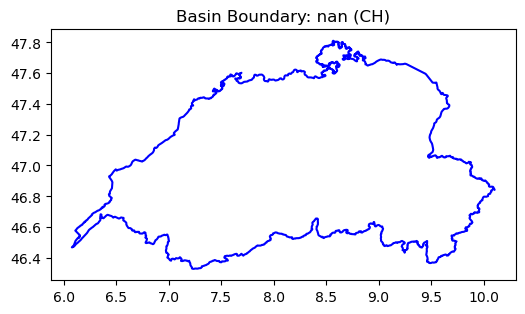

In [14]:
# SPECIFIC TO THE WFD SHAPEFILE

object_id_to_select = 21
pd_basin = basins[basins['OBJECTID'] == object_id_to_select]

if not pd_basin.empty:
    if pd_basin.iloc[0]['SubUnitNam'] is not None:
        print(f"Successfully selected sub unit {pd_basin.iloc[0]['SubUnitNam']} in the river basin: {pd_basin.iloc[0]['RBDName']}")
    else:
        print(f"Successfully selected river basin: {pd_basin.iloc[0]['RBDName']}")
    
    # Store the single basin payload and extract the geometry as WKT for API requests
    my_basin = pd_basin.iloc[[0]]
    
    # Simplify the geometry (reduces vertices drastically but keeps shape)
    basin_wkt = my_basin.iloc[0].geometry.simplify(0.05).wkt

    import matplotlib.pyplot as plt
    
    # Get basin name for plot title
    basin_name = f"{my_basin.iloc[0]['RBDName'] if my_basin.iloc[0]['SubUnitNam'] is None else my_basin.iloc[0]['SubUnitNam']} ({my_basin.iloc[0]['C_CD']})"

    # Plot our basin outline as a reference
    fig, ax = plt.subplots(figsize=(6, 6))
    my_basin.plot(ax=ax, facecolor="none", edgecolor="blue", linewidth=1.5)
    plt.title(f"Basin Boundary: {basin_name}")
    plt.show()    
else:
    print(f"Basin with OBJECTID {object_id_to_select} not found. Verify the ID exists.")

## 2. Set the search parameters and configure the request, to match the selected water basin's extent.  

Instead of generating a generic polygon for our search requests, we can inject our new `basin_wkt` directly into our CDSE OData API request to find HR-WSI products actively covering our chosen Alpine river basin.

In [15]:
# Set up the parameters

# Modify our query parameters with the WKT geometry and a specific product date to find products intersecting our selected basin
dataset_id = HRWSI_snow_collection['GFSC']['dataset_id']

product_date = "2026-04-23"
start_date = product_date
end_date = product_date
CLOUD_COVER_MAX = 30.00

params_basin = {
    "$select": "Name,Id", # to only keep the products name, the product ID in the output result
    "$filter": (
        f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'datasetIdentifier' and att/OData.CSC.StringAttribute/Value eq '{dataset_id}') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{basin_wkt}') and "
        f"ContentDate/Start ge '{start_date}T00:00:00.000Z' and "
        f"ContentDate/Start le '{end_date}T23:59:59.999Z' and "
        f"Attributes/OData.CSC.DoubleAttribute/any(att:att/Name eq 'cloudCover' and att/OData.CSC.DoubleAttribute/Value le {CLOUD_COVER_MAX})"
    ),
    "$expand": "Attributes",
    "$count": "false",
    "$top": 100
}

## 3. Execute the request and download the output data.

In [16]:
# Execute the request

print("Executing query for products intersecting our selected basin...")
try:
    basin_results = execute_request(params_basin)
    pd.DataFrame.from_dict(basin_results)
except requests.exceptions.HTTPError as http_err:
    print(f"HTTP error: {http_err} - Response: {response.text}")
except requests.exceptions.RequestException as err:
    print(f"Request error: {err}")

Executing query for products intersecting our selected basin...
Number of results: 8


In [17]:
if len(basin_results) > 0:
    access_token = get_access_token(credentials["username"], credentials["password"])
    headers = {"Authorization": f"Bearer {access_token}"}
    for product in basin_results:
        download_products(product, headers, 0)
else:
    print("No intersecting products found to download.")

Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32TLS_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32TMT_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32TLT_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32UMU_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32TNT_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T31TGM_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32TNS_20260423P7D_COMB_V102
Zip downloaded and extracted to: CLMS_WSI_GFSC_060m_T32TMS_20260423P7D_COMB_V102


## 4. Read the downloaded product and crop it based on the basin boundaries.

We use `rasterio`'s `mask` tool to crop the local image payload to the true shape/boundary of the river basin we extracted.

We also define a function that reads the colormap provided in each product folder. Legends are provided in .clr, .qml, .sld and .lyrx formats. Here, we use the .clr legend file.

In [18]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import glob
import math
import rasterio
from rasterio.mask import mask

# Define a function to load the colormap from the legend .clr file
def load_colormap(product_dir, search_pattern):
    """Loads an official colormap from the product's legend folder."""
    clr_files = glob.glob(os.path.join(product_dir, 'legend', search_pattern))
    if not clr_files:
        return None, None
    try:
        colors = np.zeros((256, 4))
        labels = {}
        with open(clr_files[0], 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 4:
                    try:
                        val = int(parts[0])
                        if val < 256:
                            r, g, b = float(parts[1])/255., float(parts[2])/255., float(parts[3])/255.
                            a = 1.0
                            if len(parts) > 4:
                                try:
                                    a = float(parts[4])/255.
                                except ValueError:
                                    pass # Ignore if alpha column contains text
                            colors[val] = [r, g, b, a]
                            
                            # Parse label (text after RGBA)
                            label_start_idx = 5 if len(parts) > 5 and parts[4].isdigit() else 4
                            if len(parts) > label_start_idx:
                                labels[val] = " ".join(parts[label_start_idx:])
                                
                    except ValueError:
                        continue # Ignore rows that don't start with an integer
        print(f"Loaded official colormap from {os.path.basename(clr_files[0])}")
        return ListedColormap(colors), labels
    except Exception as e:
        print(f"Error loading colormap: {e}")
        return None, None

#### Display each GFSC product in a separate subplot by masking the raster with the basin geometry
All snow products include several layers, including quality layers. In this example, we will display the GF layer in `.tif` format, which contains the snow fraction map.  


Loaded official colormap from clms_wsi_gap-filled-fractional-snow-cover_europe_utm_60m_daily_v1_GF.clr


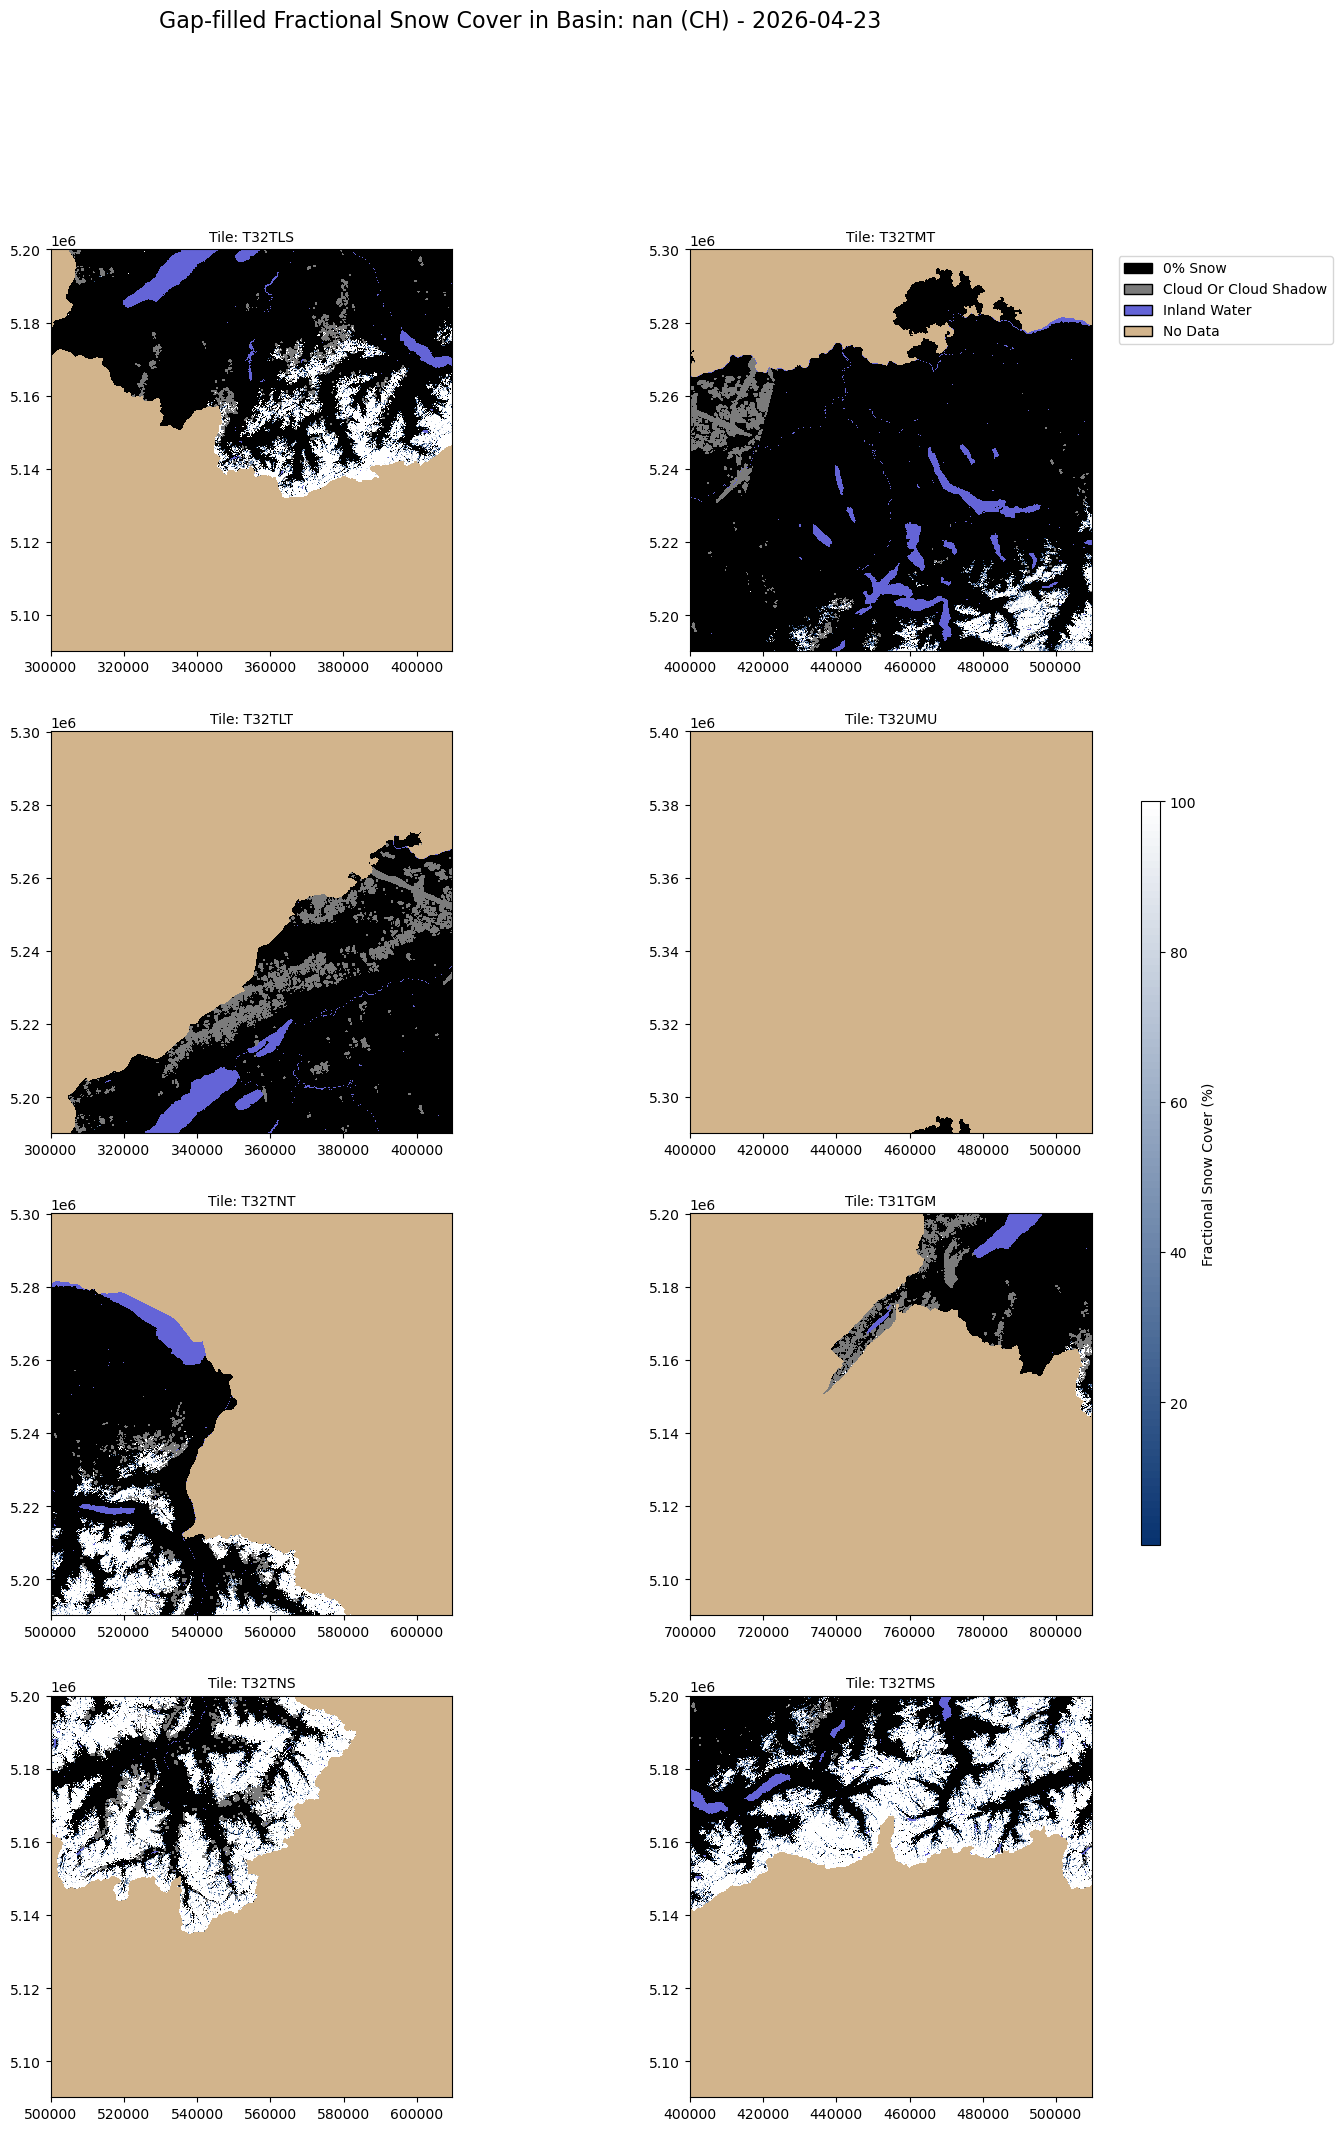

In [19]:
# Compute the layout of the subplot grid
num_tiles = len(basin_results)
num_cols = 2
num_rows = math.ceil(num_tiles / num_cols)

# Create the figure and subplot grid
fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, 6 * num_rows), squeeze=False)

# Define the color used for NoData pixels
NODATA_COLOR = 'tan'

# Initialize colormap variables
custom_cmap, custom_labels = None, None


# Loop through all downloaded products
for idx, result in enumerate(basin_results):
    # Determine subplot position
    row = idx // num_cols
    col = idx % num_cols
    ax = axes[row, col]
    
    # Get the product directory name
    product_dir = result['Name']

    # Skip missing directories
    if not product_dir or not os.path.isdir(product_dir):
        ax.set_title(f"Not found: {product_dir}")
        ax.axis('off')
        continue
    
    # Load the custom colormap only once
    if custom_cmap is None:
        custom_cmap, custom_labels = load_colormap(product_dir, '*_GF.clr')
    
    # Search for the gap-filled snow cover raster with suffix GF.tif
    gf_file = glob.glob(os.path.join(product_dir, '*_GF.tif'))

    # Skip if the raster is missing
    if not gf_file:
        ax.set_title(f"Missing TIF: {product_dir}")
        ax.axis('off')
        continue
        
    # Open the raster file
    with rasterio.open(gf_file[0]) as src:
        # Reproject the basin geometry if CRS differs from raster CRS
        if my_basin.crs != src.crs:
            my_basin_proj = my_basin.to_crs(src.crs)
        else:
            my_basin_proj = my_basin

        try:
            # Mask the raster using the basin geometry
            out_image, out_transform = mask(src, my_basin_proj.geometry, crop=False)

            # Extract the first raster band
            gf_data = out_image[0]

            if custom_cmap is not None:
                # Use the product colormap
                cmap = custom_cmap
                gf_display = gf_data
                vmax = 255
            else:
                # Use a default blue colormap
                cmap = plt.cm.Blues

                # Define colors for invalid or saturated values
                cmap.set_bad(color=NODATA_COLOR)
                cmap.set_over(color='red')
                # Mask values above 100
                gf_display = np.ma.masked_where(gf_data > 100, gf_data)
                vmax = 100
            
            # Compute raster extent for georeferenced displays
            extent = (
                out_transform[2], 
                out_transform[2] + out_transform[0] * gf_data.shape[1],
                out_transform[5] + out_transform[4] * gf_data.shape[0], 
                out_transform[5]
            )

            # Set subplot background color
            ax.set_facecolor(NODATA_COLOR)

            # Display the raster
            im = ax.imshow(gf_display, cmap=cmap, vmin=0, vmax=vmax, interpolation='nearest', extent=extent)
            
            # Extract tile identifier from product name
            title_prefix = product_dir.split('_')[4] if len(product_dir.split('_')) > 4 else product_dir

            # Set subplot title
            ax.set_title(f'Tile: {title_prefix}', fontsize=10)
            
        except ValueError:
            # Handle cases where the basin does not intersect the raster
            ax.set_title(f"No basin overlap for {product_dir}", fontsize=10)
            ax.axis('off')

# Hide empty subplots if the grid is not fully used
for idx in range(num_tiles, num_rows * num_cols):
    row = idx // num_cols
    col = idx % num_cols
    axes[row, col].axis('off')

# Add a global figure title
fig.suptitle(f'Gap-filled Fractional Snow Cover in Basin: {basin_name} - {product_date}', fontsize=16)

# Create colorbar and legend if a custom colormap exists
if custom_labels is not None:
    import matplotlib.patches as mpatches
    import matplotlib.colors as mcolors
    import matplotlib.cm as cm
    
    sm = cm.ScalarMappable(norm=mcolors.Normalize(vmin=1, vmax=100), 
                           cmap=ListedColormap(custom_cmap.colors[1:101]))
    cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.015, pad=0.04, aspect=40)
    cbar.set_label('Fractional Snow Cover (%)')
    
    legend_patches = []
    for v, lbl in custom_labels.items():
        if v == 0 or v > 100:
            c = NODATA_COLOR if v == 255 else custom_cmap.colors[v]
            legend_patches.append(mpatches.Patch(facecolor=c, label=lbl.title(), edgecolor='black'))
    
    if legend_patches:
        axes[0, -1].legend(handles=legend_patches, bbox_to_anchor=(1.05, 1), loc='upper left')
else:
    # Add a default colorbar if no custom colormap exists
    if 'im' in locals():
        fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.015, pad=0.04, label='Pixel Values')

plt.show()

#### Display all GFSC product in the same plot by masking the raster with the basin geometry

Loaded official colormap from clms_wsi_gap-filled-fractional-snow-cover_europe_utm_60m_daily_v1_GF.clr


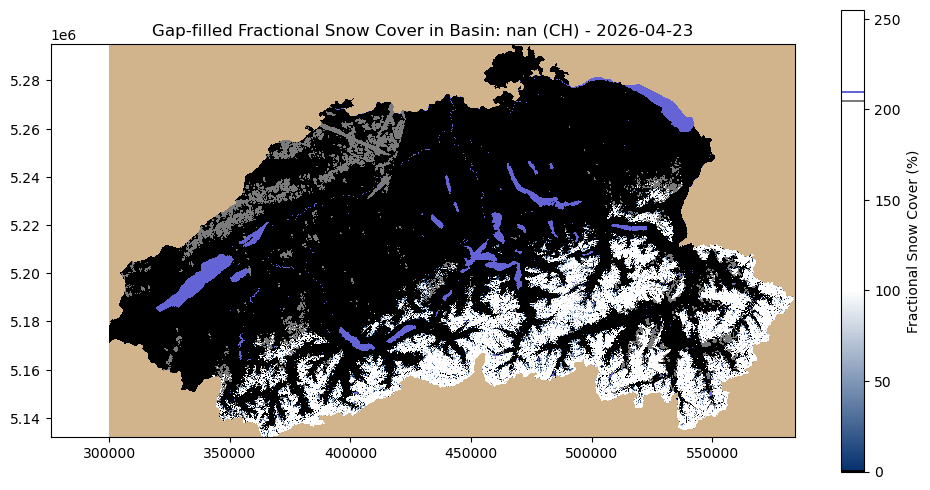

In [20]:
# Create a single figure
fig, ax = plt.subplots(figsize=(12, 12))

NODATA_COLOR = 'tan'
custom_cmap, custom_labels = None, None

# Loop through all products
for result in basin_results:

    product_dir = result['Name']

    if not product_dir or not os.path.isdir(product_dir):
        continue

    # Load colormap only once
    if custom_cmap is None:
        custom_cmap, custom_labels = load_colormap(product_dir, '*_GF.clr')

    gf_file = glob.glob(os.path.join(product_dir, '*_GF.tif'))

    if not gf_file:
        continue

    with rasterio.open(gf_file[0]) as src:

        # Reproject basin if necessary
        if my_basin.crs != src.crs:
            my_basin_proj = my_basin.to_crs(src.crs)
        else:
            my_basin_proj = my_basin

        try:
            # Mask raster with basin geometry
            out_image, out_transform = mask(
                src,
                my_basin_proj.geometry,
                crop=False
            )

            gf_data = out_image[0]

            # Configure colormap
            if custom_cmap is not None:
                # Copy colormap to safely modify bad values
                cmap = custom_cmap.copy()

                # Display NoData pixels in tan color
                cmap.set_bad(color=NODATA_COLOR)

                # Mask NoData values
                gf_display = np.ma.masked_where(gf_data == 255, gf_data)

                vmax = 255
            else:
                cmap = plt.cm.Blues
                gf_display = np.ma.masked_where(gf_data > 100, gf_data)
                vmax = 100

            # Compute raster extent
            extent = (
                out_transform[2],
                out_transform[2] + out_transform[0] * gf_data.shape[1],
                out_transform[5] + out_transform[4] * gf_data.shape[0],
                out_transform[5]
            )

            # Plot tile on the same axes
            im = ax.imshow(
                gf_display,
                cmap=cmap,
                vmin=0,
                vmax=vmax,
                interpolation='nearest',
                extent=extent
            )

        except ValueError:
            continue

# Add title
ax.set_title(f'Gap-filled Fractional Snow Cover in Basin: {basin_name} - {product_date}')

# Add colorbar
fig.colorbar(im, ax=ax, label='Fractional Snow Cover (%)',shrink=0.5)

# Get basin bounds
xmin, ymin, xmax, ymax = my_basin_proj.total_bounds
# Fix map extent
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Display final figure
plt.show()

## 5. Filter observations with quality layer informations: by sensor type (Optical vs. Radar) and observation age (how out-dated the gap-filled pixels are).
The Gap-filled GFSC product generates a continuous snow cover layer combining several inputs. The following `.tif` layers contain metadata explaining the origin of each pixel:
- `_QAFLAGS.tif`: Bit-encoded quality flags. **Bit 7** tells us if the pixel came from an **Optical sensor (0)** vs a **Radar sensor (1)**.
- `_AT.tif`: Unix timestamp returning exactly when the pixel was acquired. We can differentiate pixels retrieved more than a few days ago.

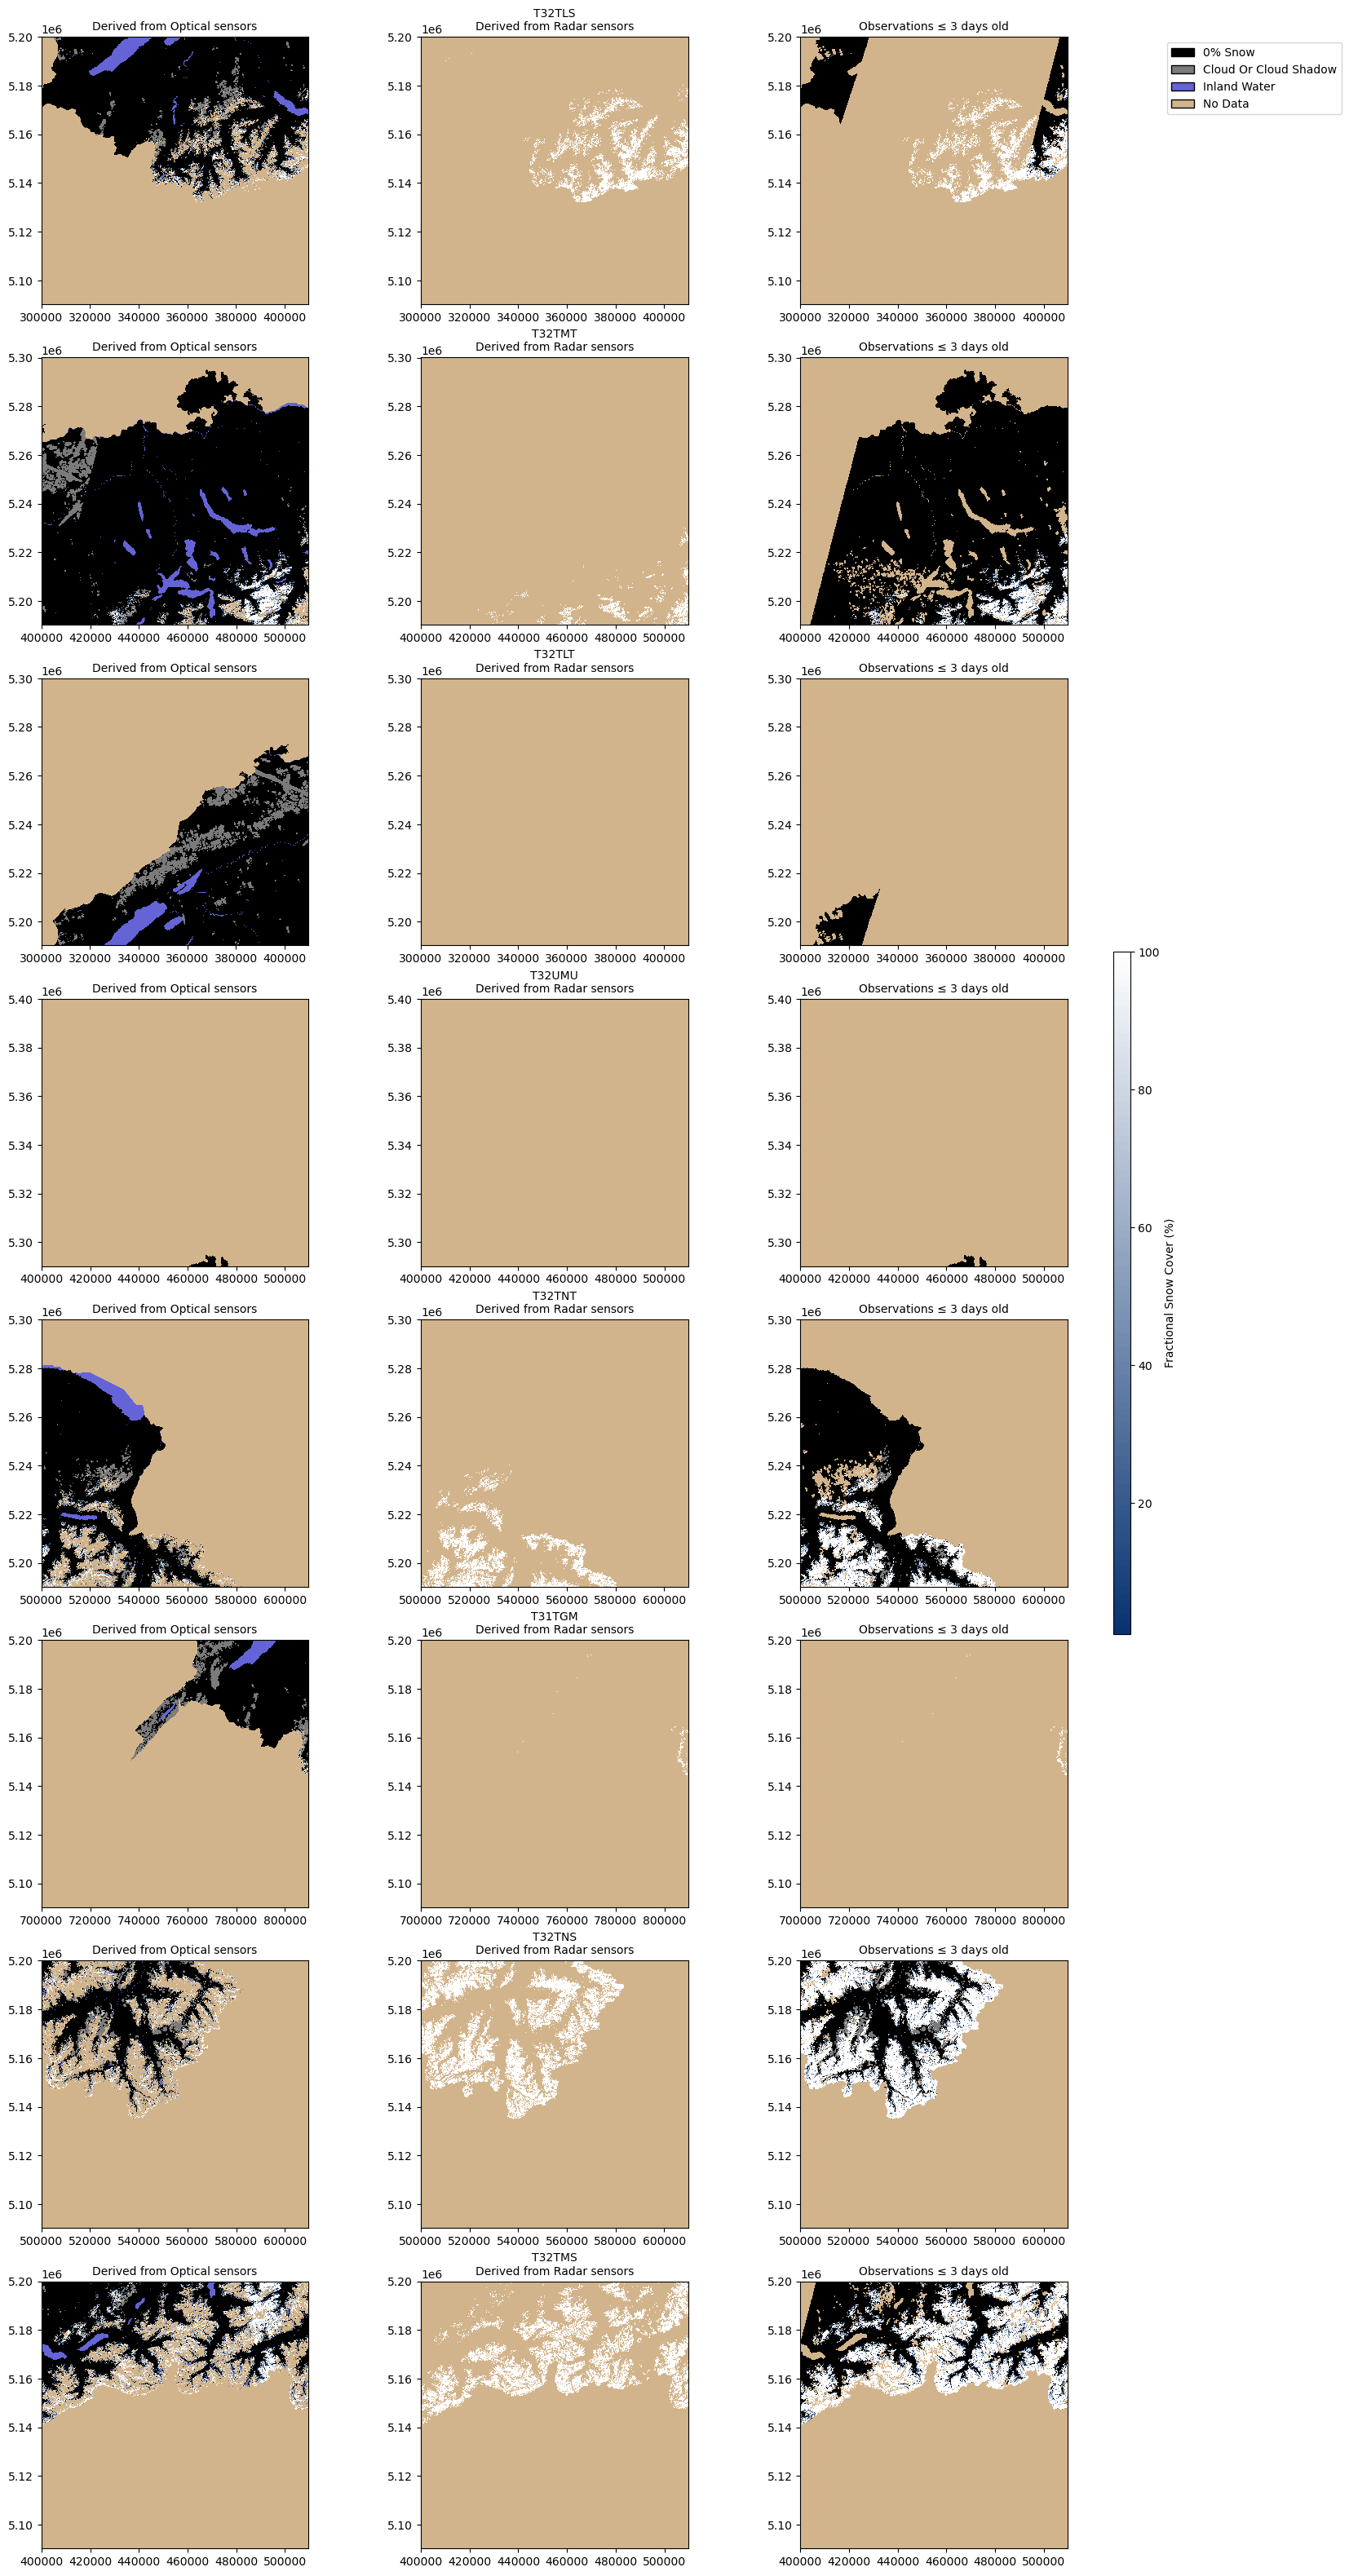

In [21]:
# Number of products to display
num_tiles = len(basin_results)
    
# Create a figure with 3 columns for each product:
# - Optical-derived snow cover
# - Radar-derived snow cover
# - Recent observations only
fig, axes = plt.subplots(num_tiles, 3, figsize=(18, 5 * num_tiles), squeeze=False)

# Loop through all products
for idx, product in enumerate(basin_results):
    # Get product directory
    product_dir = product['Name']

    # Search for required raster files
    qa_file = glob.glob(os.path.join(product_dir, '*_QAFLAGS.tif'))
    at_file = glob.glob(os.path.join(product_dir, '*_AT.tif'))
    gf_file = glob.glob(os.path.join(product_dir, '*_GF.tif'))
    
    # Skip products with missing files
    if not (qa_file and at_file and gf_file):
        for col in range(3):
            axes[idx, col].set_title(f"Missing data: {product_dir}")
        continue
        
    try:
        # Open all raster products
        with rasterio.open(gf_file[0]) as src_gf, rasterio.open(qa_file[0]) as src_qa, rasterio.open(at_file[0]) as src_at:
            # Reproject basin geometry if CRS differs from raster CRS
            if my_basin.crs != src_gf.crs:
                my_basin_proj = my_basin.to_crs(src_gf.crs)
            else:
                my_basin_proj = my_basin

            # Mask rasters using the basin geometry
            gf_image, _ = mask(src_gf, my_basin_proj.geometry, crop=False)
            qa_image, out_transform = mask(src_qa, my_basin_proj.geometry, crop=False)
            at_image, _ = mask(src_at, my_basin_proj.geometry, crop=False)
            
            # Extract raster arrays
            gf_data = gf_image[0]
            qa_data = qa_image[0]
            at_data = at_image[0]
            
        # Extract Bit 7 for sensor type (0 = optical observation, 1 = radar observation)
        is_radar = (qa_data >> 7) & 1
        
        # Compute pixel age: observation date midnight - _AT.tif pixel timestamp
        from datetime import datetime
        import time
        date_str = product_dir.split('_')[5][:8]
        obs_date = datetime.strptime(date_str, "%Y%m%d")
        midnight_unix = time.mktime(obs_date.timetuple())
        
        # Any acquisition timestamp during the product date should map to an age of 0.
        # We add 1 day (86400 seconds) to find the end of the day, calculate the difference, and floor it downhill.
        end_of_day_unix = midnight_unix + (60 * 60 * 24)
        age_days = np.floor((end_of_day_unix - at_data) / (60 * 60 * 24))
        age_days = np.maximum(0, age_days)  # clamp negative values in case pixels are slightly newer
        
        # Compute raster spatial extent
        extent = (
            out_transform[2], 
            out_transform[2] + out_transform[0] * qa_data.shape[1],
            out_transform[5] + out_transform[4] * qa_data.shape[0], 
            out_transform[5]
        )
        
        # Configure display settings
        if 'custom_cmap' in locals() and custom_cmap is not None:
            # Use official product colormap
            opts = dict(cmap=custom_cmap, vmin=0, vmax=255, interpolation='nearest', extent=extent)

            # Keep only optical-derived pixels
            # Replace excluded pixels with NoData value (255)
            gf_optical = np.where(is_radar == 0, gf_data, 255)

            # Keep only radar-derived pixels
            gf_radar = np.where(is_radar == 1, gf_data, 255)

            # Keep only recent observations (≤ 3 days old)
            gf_recent = np.where(age_days <= 3.0, gf_data, 255)
        else:
            # Use default blue colormap
            opts = dict(cmap='Blues', vmin=0, vmax=100, extent=extent)

            # Replace excluded pixels with NaN
            gf_optical = np.where(is_radar == 0, gf_data, np.nan)
            gf_radar = np.where(is_radar == 1, gf_data, np.nan)
            gf_recent = np.where(age_days <= 3.0, gf_data, np.nan)
            
            # Mask out 'no data'/clouds again
            gf_optical = np.ma.masked_where((gf_optical > 100) | np.isnan(gf_optical), gf_optical)
            gf_radar = np.ma.masked_where((gf_radar > 100) | np.isnan(gf_radar), gf_radar)
            gf_recent = np.ma.masked_where((gf_recent > 100) | np.isnan(gf_recent), gf_recent)
        
        # Set the axes backgrounds for masked out/transparent areas
        for col in range(3):
            axes[idx, col].set_facecolor(NODATA_COLOR)
            
        # Display optical-derived snow cover
        im0 = axes[idx, 0].imshow(gf_optical, **opts)
        product_tile = product_dir.split('_')[4]
        axes[idx, 0].set_title(f'Derived from Optical sensors', fontsize=10)
        
        # Display radar-derived snow cover
        im1 = axes[idx, 1].imshow(gf_radar, **opts)
        axes[idx, 1].set_title(f'{product_tile}\nDerived from Radar sensors', fontsize=10)
        
        # Display recent observations only
        im2 = axes[idx, 2].imshow(gf_recent, **opts)
        axes[idx, 2].set_title(f'Observations ≤ 3 days old', fontsize=10)
        
    except ValueError:
        for col in range(3):
            axes[idx, col].set_title(f"No basin overlap for {product_dir}", fontsize=10)

# Create legends and colorbars
if 'custom_labels' in locals() and custom_labels is not None:
    import matplotlib.patches as mpatches
    import matplotlib.colors as mcolors
    import matplotlib.cm as cm
    
    # Shared primary colorbar covering all axes restricted to the 1-100 snow fraction range
    sm = cm.ScalarMappable(norm=mcolors.Normalize(vmin=1, vmax=100), 
                           cmap=ListedColormap(custom_cmap.colors[1:101]))
    cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.015, pad=0.04, aspect=40)
    cbar.set_label('Fractional Snow Cover (%)')
    
    # Create a supplementary categorical legend for special values
    legend_patches = []
    for v, lbl in custom_labels.items():
        if v == 0 or v > 100:  # Grab 0% snow, clouds, water, nodata
            c = NODATA_COLOR if v == 255 else custom_cmap.colors[v]
            legend_patches.append(mpatches.Patch(facecolor=c, label=lbl.title(), edgecolor='black'))
    
    # Add legend to the figure
    if legend_patches:
        # Anchor next to the rightmost axis of the top row (or overall figure)
        axes[0, -1].legend(handles=legend_patches, bbox_to_anchor=(1.35, 1), loc='upper left')
else:
    # Fallback colorbar if no custom colormap exists
    fig.colorbar(im2, ax=axes.ravel().tolist(), fraction=0.015, pad=0.04, label='Pixel Values')

# Display final figure
plt.show()

### 6. Explore Snow Phenology (SPS2) Products

Now let's query and explore the **Snow Phenology** yearly product for 2018-2019 hydrological year. We will download the product overlapping our selected river basin and visualize layers like **SCD** (Snow Cover Duration), **SCM** (Snow Cover Melt), and **SCO** (Snow Cover Onset).

In [22]:
# Select SPS2 Dataset ID
dataset_id_sps = HRWSI_snow_collection['SPS2']['dataset_id']

# Yearly product, query for 2018
start_date = "2018-01-01"
end_date = "2018-12-31"

params_sps = {
    "$select": "Name,Id", # to only keep the products name, the product ID in the output result
    "$filter": (
        f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'datasetIdentifier' and att/OData.CSC.StringAttribute/Value eq '{dataset_id_sps}') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{basin_wkt}') and "
        f"ContentDate/Start ge '{start_date}T00:00:00.000Z' and "
        f"ContentDate/Start le '{end_date}T23:59:59.999Z'"
    ),
    "$expand": "Attributes",
    "$count": "false",
    "$top": 100
}

print("Executing query for SPS2 products intersecting our selected basin...")
try:
    sps_results = execute_request(params_sps)
except Exception as e:
    print(f"Request error: {e}")

if len(sps_results) > 0:
    print(f"Downloading intersecting SPS2 products...")
    access_token = get_access_token(credentials["username"], credentials["password"])
    headers_sps = {"Authorization": f"Bearer {access_token}"}
    
    for product in sps_results:
        if os.path.exists(product['Name']):
            print(f"Product directory already exists, skipping download: {product['Name']}")
            continue
        download_products(product, headers_sps, 0)
else:
    print("No intersecting SPS2 products found to download.")

Executing query for SPS2 products intersecting our selected basin...
Number of results: 9
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32UMU_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32TNS_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32TMS_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32TMT_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32TNT_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T31TGM_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32TLS_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T31TGN_20180901P1Y_S2_V100
Zip downloaded and extracted to: CLMS_WSI_SP_020m_T32TLT_20180901P1Y_S2_V100


#### Display each SPS2 product in a separate subplot by masking the raster with the basin geometry

First set a function to read the official color map of the product.

In [23]:
# Define a function to load the colormap from the legend .clr file
def load_colormap_sps(product_dir, search_pattern):
    """Loads an official colormap specifically handling large values (> 255) typically found in DOY layers (e.g. 365, 65535 NodeData)."""
    clr_files = glob.glob(os.path.join(product_dir, 'legend', search_pattern))

    if not clr_files:
        return None, None
    try:
        color_dict = {}
        labels = {}
        with open(clr_files[0], 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 4 and parts[0].isdigit():
                    try:
                        val = int(parts[0])
                        r, g, b = float(parts[1])/255., float(parts[2])/255., float(parts[3])/255.
                        a = 1.0
                        if len(parts) > 4:
                            try:
                                a = float(parts[4])/255.
                            except ValueError:
                                pass
                        color_dict[val] = (r, g, b, a)
                        
                        label_start_idx = 5 if len(parts) > 5 and parts[4].isdigit() else 4
                        if len(parts) > label_start_idx:
                            labels[val] = " ".join(parts[label_start_idx:])
                    except ValueError:
                        continue
        return color_dict, labels
    except Exception as e:
        print(f"Error loading colormap: {e}")
        return None, None


Then prepare the plots after the download

Plotting Snow Phenology layers for 9 products...


/tmp/ipykernel_16595/1335325883.py:105: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  legend_patches.append(mpatches.Patch(color=c, label=custom_labels[v].title(), edgecolor='black'))
/tmp/ipykernel_16595/1335325883.py:105: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  legend_patches.append(mpatches.Patch(color=c, label=custom_labels[v].title(), edgecolor='black'))
/tmp/ipykernel_16595/1335325883.py:105: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  legend_patches.append(mpatches.Patch(color=c, label=custom_labels[v].title(), edgecolor='black'))


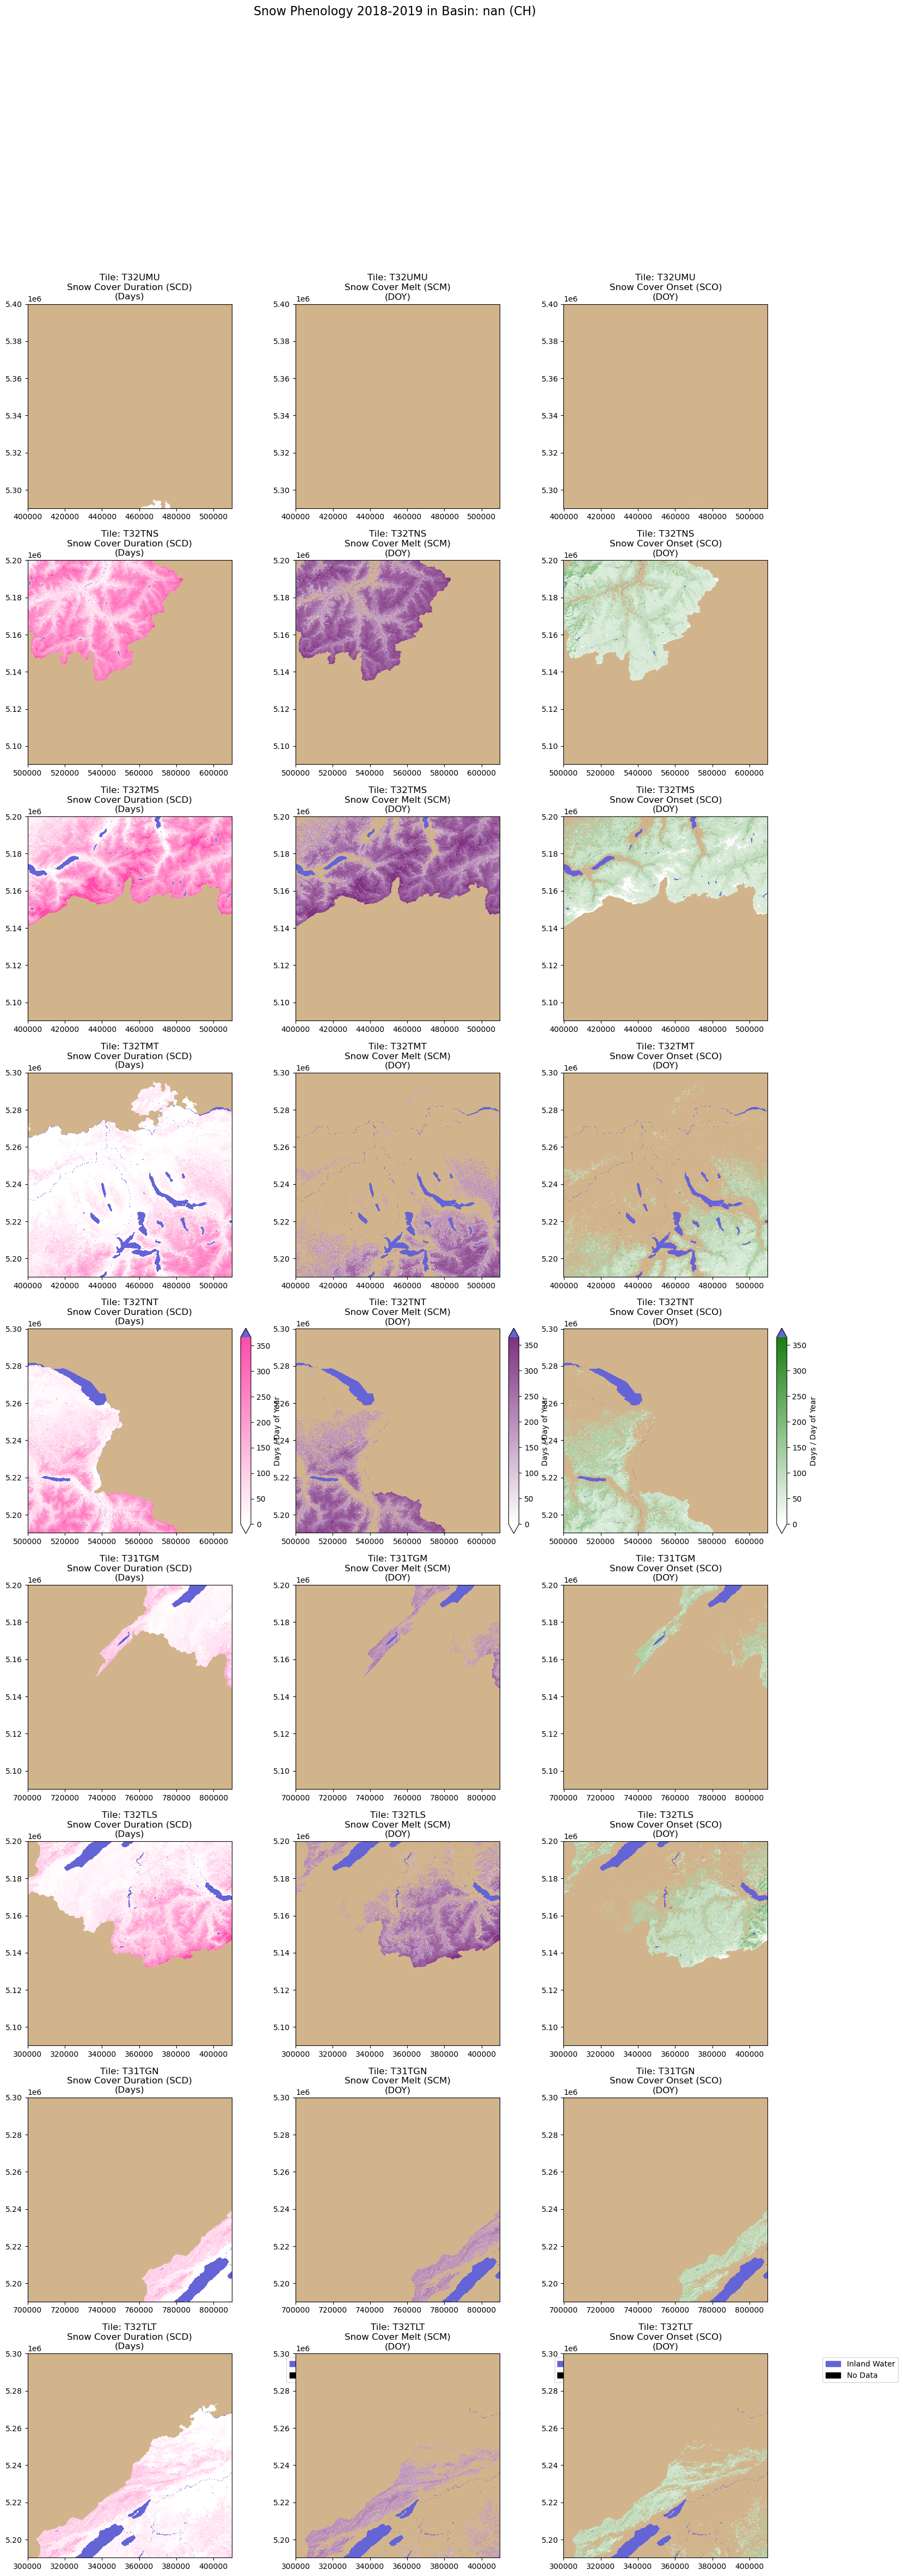

In [24]:
if len(sps_results) > 0:
    num_tiles_sps = len(sps_results)
    print(f"Plotting Snow Phenology layers for {num_tiles_sps} products...")
    
    fig, axes = plt.subplots(num_tiles_sps, 3, figsize=(18, 6 * num_tiles_sps), squeeze=False)
    NODATA_COLOR = 'tan'
    custom_cmaps, custom_labelss = [None, None, None], [None, None, None] # separate colormaps for each layer type (SCD, SCM, SCO)
    
    for idx, result in enumerate(sps_results):
        sps_dir = result['Name']
        if not sps_dir or not os.path.isdir(sps_dir):
            for col in range(3):
                axes[idx, col].set_title(f"Not found: {sps_dir}", fontsize=12)
                axes[idx, col].axis('off')
            continue
            
        scd_file = glob.glob(os.path.join(sps_dir, '*_SCD.tif'))
        scm_file = glob.glob(os.path.join(sps_dir, '*_SCM.tif'))
        sco_file = glob.glob(os.path.join(sps_dir, '*_SCO.tif'))
        
        if not (scd_file and scm_file and sco_file):
            for col in range(3):
                axes[idx, col].set_title(f"Missing layers: {sps_dir}", fontsize=12)
                axes[idx, col].axis('off')
            continue
            
        layers = [
            (scd_file[0], 'Snow Cover Duration (SCD)\n(Days)', '*-SCD.clr'),
            (scm_file[0], 'Snow Cover Melt (SCM)\n(DOY)', '*-SCM.clr'),
            (sco_file[0], 'Snow Cover Onset (SCO)\n(DOY)', '*-SCO.clr')
        ]
        
        for i, (tiff_path, title, clr_pattern) in enumerate(layers):
            ax = axes[idx, i]
            if custom_cmaps[i] is None or custom_labelss[i] is None:
                custom_cmap, custom_labels = load_colormap_sps(sps_dir, clr_pattern)
                custom_cmaps[i] = custom_cmap
                custom_labelss[i] = custom_labels
            else:
                custom_cmap, custom_labels = custom_cmaps[i], custom_labelss[i]
            
            with rasterio.open(tiff_path) as src:
                if my_basin.crs != src.crs:
                    my_basin_proj = my_basin.to_crs(src.crs)
                else:
                    my_basin_proj = my_basin

                try:
                    out_image, out_transform = mask(src, my_basin_proj.geometry, crop=False)
                    layer_data = out_image[0]
                    
                    extent = (
                        out_transform[2], 
                        out_transform[2] + out_transform[0] * layer_data.shape[1],
                        out_transform[5] + out_transform[4] * layer_data.shape[0], 
                        out_transform[5]
                    )

                    ax.set_facecolor(NODATA_COLOR)
                    
                    if custom_cmap is not None:
                        # Extract bounded colormap for values 1 to 366
                        valid_min = 0
                        valid_max = min(max([k for k in custom_cmap.keys() if k <= 366], default=366), 366)
                        
                        cmap_colors = [custom_cmap.get(v, (1, 1, 1, 0)) for v in range(valid_min, valid_max + 1)]
                        cmap = ListedColormap(cmap_colors)
                        
                        # Specify out of bounds colors using matplotlib native tools
                        cmap.set_over(custom_cmap.get(420, (0.4, 0.4, 0.8, 1))) # e.g. inland water
                        cmap.set_bad(custom_cmap.get(65535, (0.8, 0.8, 0.8, 1))) # e.g. nodata
                        cmap.set_bad(color=NODATA_COLOR)
                        
                        # Map categorical limits explicitly
                        gf_display = layer_data.copy()
                        gf_display[gf_display == 420] = valid_max + 1 # mapped to 'over'
                        
                        masked_data = np.ma.masked_where(gf_display == 65535, gf_display)
                        
                        im = ax.imshow(masked_data, cmap=cmap, vmin=valid_min, vmax=valid_max, interpolation='nearest', extent=extent)
                    else:
                        # Fallback if no .clr found
                        masked_data = np.ma.masked_where((layer_data == 0) | (layer_data > 366), layer_data)
                        cmap = plt.get_cmap('viridis').copy()
                        cmap.set_bad(color=NODATA_COLOR)
                        im = ax.imshow(masked_data, cmap=cmap, interpolation='nearest', extent=extent)

                    title_prefix = sps_dir.split('_')[4] if len(sps_dir.split('_')) > 4 else sps_dir
                    ax.set_title(f'Tile: {title_prefix}\n{title}', fontsize=12)
                    
                    # Add colorbar appropriately
                    if idx == num_tiles_sps - 1:
                        if custom_labels is not None:
                            import matplotlib.patches as mpatches
                            
                            cbar = fig.colorbar(im, ax=axes[:, i], fraction=0.046, pad=0.04, extend='both')
                            cbar.set_label('Days / Day of Year')
                            
                            # Legends for categorical values appropriately
                            legend_patches = []
                            for v in sorted(custom_cmap.keys()):
                                if v > 366:
                                    if v in custom_labels:
                                        c = custom_cmap[v]
                                        legend_patches.append(mpatches.Patch(color=c, label=custom_labels[v].title(), edgecolor='black'))
                            
                            if legend_patches:
                                # Display one legend next to the colorbar
                                ax.legend(handles=legend_patches, bbox_to_anchor=(1.25, 1), loc='upper left')
                        else:
                            cbar = fig.colorbar(im, ax=axes[:, i], fraction=0.046, pad=0.04)
                            cbar.set_label('Days / Day of Year')
                    
                except ValueError:
                    ax.set_title(f"No basin overlap:\n{title}", fontsize=12)
                    ax.axis('off')
        
    fig.suptitle(f'Snow Phenology 2018-2019 in Basin: {basin_name}', fontsize=16)
    plt.show()

# SUMMARY
This notebook demonstrates how to access, filter, download, and visualize HR-WSI snow products using the OData API from the Copernicus Data Space Ecosystem (CDSE). Although focused on snow products, the workflow can be adapted to other HR-WSI datasets provided the corresponding OData DatasetID is known.

The notebook includes examples of querying and downloading products based on:
- A specific dataset
- A user-defined date range
- An Area of Interest (AOI) defined either by:
    - a WKT geometry, or
    - a custom shapefile
- A maximum cloud cover threshold

In addition, the notebook demonstrates how to:
- Visualize HR-WSI snow products with their associated legends
- Display data at both:
    - Sentinel-2 tile level, and
    - AOI level
- Plot products clipped to a user-defined shapefile
- Use quality layers to filter the information according to selected quality criteria